# Analyse d'image - Classification

## 1. Chargement des données

In [14]:
import pandas as pnd
import numpy as np
from matplotlib import pyplot as plt
from sklearn.model_selection import train_test_split
import tensorflow as tf
import keras
tf.config.set_visible_devices([], 'GPU')

# Definition de la longueur et de la largeur de l'image
LONGUEUR_IMAGE = 28 
LARGEUR_IMAGE = 28

# Chargement de la longeur et de la largeur de l'image
observations_entrainement = pnd.read_csv('datas/fashion-mnist_train.csv')


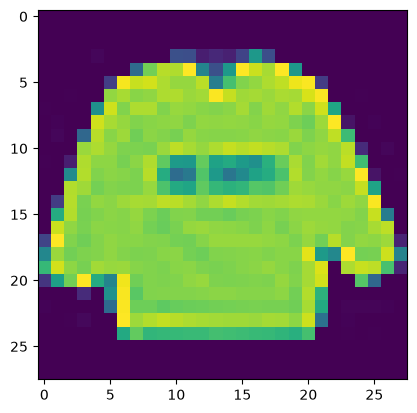

In [15]:
#On exclut la première colonne (les labels) pour constituer un tableau de pixels
X = np.array(observations_entrainement.iloc[:, 1:])

premiereImage = X[0]
premiereImage = premiereImage.reshape([LONGUEUR_IMAGE,LARGEUR_IMAGE])
plt.imshow(premiereImage)
plt.show()

## 2. Préparation des données d'apprentissage

In [16]:
#On crée des catégories à l'aide du module Keras
y = keras.utils.to_categorical(np.array(observations_entrainement.iloc[:,0]))

#Répartition des données d'entrainement en données d'apprentissage et données de validation
#80% de donnée d'apprentissage et 20% de donnée de validation
X_apprentissage, X_validation, y_apprentissage, y_validation = train_test_split(X, y, test_size=0.2, random_state=13)

In [17]:
# On redimensionne les images au format 28*28 et on réalise un scaling sur les données des pixels
X_apprentissage = X_apprentissage.reshape(X_apprentissage.shape[0],
                                          LARGEUR_IMAGE,
                                          LONGUEUR_IMAGE, 1)
X_apprentissage = X_apprentissage.astype('float32')
X_apprentissage /= 255

X_validation = X_validation.reshape(X_validation.shape[0],
                                    LARGEUR_IMAGE,
                                    LONGUEUR_IMAGE, 1)
X_validation = X_validation.astype('float32')
X_validation /= 255

## 3. Préparation des données de tests

In [18]:
#Preparation des données de tests
observations_test = pnd.read_csv('datas/fashion-mnist_test.csv')

X_test = np.array(observations_test.iloc[:, 1:])
y_test = tf.keras.utils.to_categorical(np.array(observations_test.iloc[:, 0]))

X_test = X_test.reshape(X_test.shape[0],
                        LARGEUR_IMAGE,
                        LONGUEUR_IMAGE, 1)
X_test = X_test.astype('float32')
X_test /= 255

## 4. Réseau avec une couche de convolution

In [19]:
from keras.models import Sequential
from keras.layers import Dense, Dropout, Flatten, Input
from keras.layers import Conv2D, MaxPooling2D

# On spécifie les dimensions de l'image d'entrée
dimentionImage = (LARGEUR_IMAGE, LONGUEUR_IMAGE, 1)

# On crée le réseau de neurones couche par couche
reseauNeurone1Convolution = Sequential()

# Ajout de la couche d'entrée
reseauNeurone1Convolution.add(Input(shape=dimentionImage))

#1- Ajout de la couche de convolution comportant
# 32 filtres de de taille 3x3 (Kernel) parcourant l'image
# Une fonction d'activation de type ReLU (Rectified Linear Activation)
# Une image d'entrée de 28px * 28 px
reseauNeurone1Convolution.add(Conv2D(32,
                                     kernel_size=(3, 3),
                                     activation='relu'))

#2- Définition de la fonction de pooling avec une fenêtre de 2px sur 2 px
reseauNeurone1Convolution.add(MaxPooling2D(pool_size=(2, 2)))

#3- Ajout d'une fonction d'ignorance
reseauNeurone1Convolution.add(Dropout(0.2))

#5 - On transforme en une seule ligne
reseauNeurone1Convolution.add(Flatten())

#6 - Ajout d'un réseau de neurones composé de 128 neurones avec
# une fonction d'activation de type ReLU
reseauNeurone1Convolution.add(Dense(128, activation='relu'))

#7 - Ajout d'un réseau de neurones composé de 10 neurones avec une
# fonction d'activation de type softmax
reseauNeurone1Convolution.add(Dense(10, activation='softmax'))

## 5. Compilation, apprentissage et test

In [20]:
reseauNeurone1Convolution.compile(loss=keras.losses.categorical_crossentropy,
                                  optimizer=tf.keras.optimizers.Adam(),
                                  metrics=['accuracy'])

historique_apprentissage = reseauNeurone1Convolution.fit(
    X_apprentissage,
    y_apprentissage,
    batch_size=256,
    epochs=10,
    verbose=1,
    validation_data=(X_validation, y_validation))

Epoch 1/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 9s 36ms/step - accuracy: 0.8091 - loss: 0.5488 - val_accuracy: 0.8567 - val_loss: 0.4029
Epoch 2/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 7s 35ms/step - accuracy: 0.8715 - loss: 0.3623 - val_accuracy: 0.8767 - val_loss: 0.3439
Epoch 3/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 6s 34ms/step - accuracy: 0.8864 - loss: 0.3180 - val_accuracy: 0.8878 - val_loss: 0.3170
Epoch 4/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 6s 34ms/step - accuracy: 0.8956 - loss: 0.2938 - val_accuracy: 0.8966 - val_loss: 0.2910
Epoch 5/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 6s 34ms/step - accuracy: 0.9041 - loss: 0.2672 - val_accuracy: 0.8972 - val_loss: 0.2860
Epoch 6/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 6s 34ms/step - accuracy: 0.9096 - loss: 0.2507 - val_accuracy: 0.8997 - val_loss: 0.2846
Epoch 7/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 8s 40ms/step - accuracy: 0.9149 - loss: 0.2343 - val_accuracy: 0.9013 - val_loss: 0.2738
Epoch 8/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 7s 38ms/step - accuracy: 0.9187 - loss: 0.2232 - val_accu

In [21]:
evaluation = reseauNeurone1Convolution.evaluate(X_test, y_test, verbose=0)
print('Erreur:', evaluation[0])
print('Précision:', evaluation[1])

Erreur: 0.23515690863132477
Précision: 0.9168999791145325


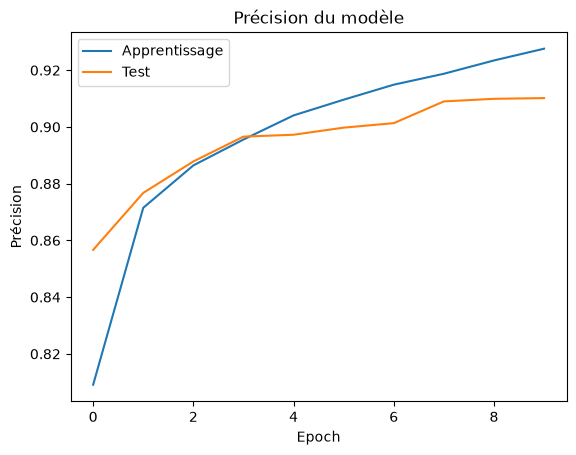

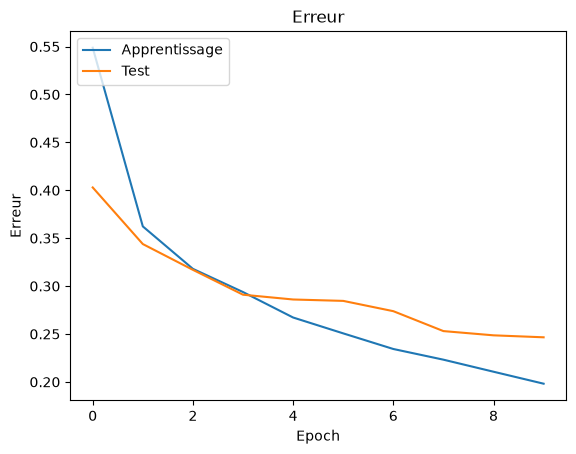

In [22]:
plt.plot(historique_apprentissage.history['accuracy'])
plt.plot(historique_apprentissage.history['val_accuracy'])
plt.title('Précision du modèle')
plt.ylabel('Précision')
plt.xlabel('Epoch')
plt.legend(['Apprentissage', 'Test'], loc='upper left')
plt.show()

# Plot training & validation loss values
plt.plot(historique_apprentissage.history['loss'])
plt.plot(historique_apprentissage.history['val_loss'])
plt.title('Erreur')
plt.ylabel('Erreur')
plt.xlabel('Epoch')
plt.legend(['Apprentissage', 'Test'], loc='upper left')
plt.show()

## 6. Augmentation du nombre de données

In [23]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

generateur_images = tf.keras.preprocessing.image.ImageDataGenerator(
    rotation_range=8,
    width_shift_range=0.08,
    shear_range=0.3,
    height_shift_range=0.08,
    zoom_range=0.08)

nouvelles_images_apprentissage = generateur_images.flow(
    X_apprentissage,
    y_apprentissage,
    batch_size=256)

nouvelles_images_validation = generateur_images.flow(
    X_validation,
    y_validation,
    batch_size=256)

In [24]:
historique_apprentissage = reseauNeurone1Convolution.fit(
    nouvelles_images_apprentissage,
    steps_per_epoch=48000//256,
    epochs=50,
    validation_data=nouvelles_images_validation,
    validation_steps=12000//256,
    verbose=1 )

evaluation = reseauNeurone1Convolution.evaluate(X_test, y_test, verbose=0)
print('Erreur :', evaluation[0])
print('Précision:', evaluation[1])

Epoch 1/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 27s 138ms/step - accuracy: 0.8262 - loss: 0.4669 - val_accuracy: 0.8443 - val_loss: 0.4184
Epoch 2/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 5s 25ms/step - accuracy: 0.8594 - loss: 0.4104 - val_accuracy: 0.8432 - val_loss: 0.4198
Epoch 3/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 25s 134ms/step - accuracy: 0.8494 - loss: 0.4055 - val_accuracy: 0.8466 - val_loss: 0.4048
Epoch 4/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 5s 24ms/step - accuracy: 0.8242 - loss: 0.4229 - val_accuracy: 0.8505 - val_loss: 0.3974
Epoch 5/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 25s 134ms/step - accuracy: 0.8551 - loss: 0.3892 - val_accuracy: 0.8615 - val_loss: 0.3732
Epoch 6/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 5s 24ms/step - accuracy: 0.8633 - loss: 0.3543 - val_accuracy: 0.8599 - val_loss: 0.3860
Epoch 7/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 25s 135ms/step - accuracy: 0.8613 - loss: 0.3722 - val_accuracy: 0.8684 - val_loss: 0.3619
Epoch 8/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 5s 24ms/step - accuracy: 0.8984 - loss: 0.3131 - 